# Step 4 — Point comparison at stations. The head-to-head, and K2

Spec: `CLAUDE.md` §6 Step 4, §5.3, §5.4. **GOES is excluded** (§5.2): it measures brightness
temperature, not LST, and is a timing instrument only. **ECOSTRESS is excluded**: it was dropped
in §5.2 after Step 3.

**Read §1b first.** Every remaining sensor is 1 km or coarser, the same footprint as Daymet, so
**this step tests measurement against interpolation, not resolution.** §5.2a requires the result
to be reported as **two findings, never one ranking**:

| comparison | footprints | what a satellite win would mean |
|---|---|---|
| satellite vs **Daymet** | 1 km vs 1 km | measurement beating interpolation — **no resolution advantage is available** |
| satellite vs **PRISM, gridMET** (4 km), **ERA5-Land** (~11 km) | finer vs coarser | partly resolution |

**The confound (§5.4).** CIMIS measures air temperature at 1.5 m over irrigated grass; satellite
LST measures the surface. On a radiative-cooling night these differ by several degrees and the
offset is not constant. Results are therefore reported **raw** (honest about what LST is) and
**bias-corrected per region and per year** (what an index product would actually do).

**Bias correction is fitted leave-one-station-out.** Fitting an offset on a region-year and then
scoring the same station-nights with it is self-fitting, and it flatters every product. Each
station's offset is fitted on the *other* stations in its region-year. Both are reported so the
size of the self-fitting effect is visible.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from shapely.geometry import Point

import common as C

plt.rcParams["mathtext.default"] = "regular"
GRIDS = ["prism", "gridmet", "daymet", "era5land"]
GRID_LABEL = {"prism": "PRISM 4 km", "gridmet": "gridMET 4 km", "daymet": "Daymet 1 km",
              "era5land": "ERA5-Land ~11 km"}
SATS = [("VIIRS", "viirs_lst_c", "viirs"), ("Aqua", "aqua_lst_c", "aqua"),
        ("Terra", "terra_lst_c", "terra")]
THRESHOLDS = [(0.0, "0 °C"), (-1.1, "−1.1 °C (30 °F)"), (-2.2, "−2.2 °C (28 °F)")]

av = pd.read_csv(C.DERIVED / "03_availability_station_nights.csv", parse_dates=["date"])
gr = pd.read_csv(C.DERIVED / "04_grid_station_nights.csv", parse_dates=["date"])
obs = av[["station", "date", "year", "region", "tmin_c", "frost"]].rename(
    columns={"tmin_c": "obs_c"})
print(f"station-nights                : {len(obs):,}")
print(f"  frost nights at 0 °C        : {int(obs.frost.sum()):,}")
print(f"gridded rows extracted        : {len(gr):,} across {gr.grid.nunique()} products")

station-nights                : 31,359
  frost nights at 0 °C        : 2,910
gridded rows extracted        : 187,173 across 4 products


## 4a — Day alignment, tested rather than assumed

PRISM assets are timestamped noon UTC rather than midnight, and each provider defines its
24-hour window its own way, while CIMIS `DayAirTmpMin` is the minimum over the local calendar
day. Rather than assume the conventions line up, each grid is matched at day offsets −1, 0 and
+1 and the alignment that minimises median absolute error is used.

In [2]:
align = {}
print(f"{'grid':<12}{'−1 day':>10}{'0':>10}{'+1 day':>10}   chosen")
for name, g in gr.groupby("grid"):
    res = {}
    for off in (-1, 0, 1):
        t = g[["station", "date", "tmin_c"]].copy()
        t["date"] = t.date - pd.Timedelta(days=off)
        mm = obs.merge(t, on=["station", "date"], how="inner")
        res[off] = (mm.tmin_c - mm.obs_c).abs().median()
    align[name] = min(res, key=res.get)
    print(f"{name:<12}{res[-1]:>10.2f}{res[0]:>10.2f}{res[1]:>10.2f}   {align[name]:+d}")
print("\nAll four align on the calendar day with no shift, so no offset is applied.")

m = obs.copy()
for name, g in gr.groupby("grid"):
    t = g[["station", "date", "tmin_c"]].copy()
    t["date"] = t.date - pd.Timedelta(days=align[name])
    m = m.merge(t.rename(columns={"tmin_c": name}), on=["station", "date"], how="left")
for _, col, flag in SATS:
    m = m.merge(av[["station", "date", flag, col]], on=["station", "date"], how="left")
print(f"joined table: {len(m):,} station-nights")

grid            −1 day         0    +1 day   chosen
daymet            2.18      1.54      2.14   +0
era5land          2.61      1.95      2.52   +0
gridmet           1.75      1.25      2.15   +0
prism             1.50      0.94      1.96   +0

All four align on the calendar day with no shift, so no offset is applied.
joined table: 31,359 station-nights


## 4b — The head-to-head

Two cautions built into the tables below.

**Matched subsets.** A satellite is only scored on nights it could see, so comparing its error
against a grid scored on *all* nights compares different weather. Every head-to-head here is run
on the **same station-nights**: those where the satellite in question has a usable retrieval. The
unmatched version is shown first to make the size of that distortion visible — it materially
flattered the satellite in the tails.

**Leave-one-station-out.** The bias-corrected numbers fit each station's offset on the other
stations in its region-year.

In [3]:
def loso_errors(df, col):
    # Error after a per-region-per-year offset fitted WITHOUT the station being scored.
    s = df.dropna(subset=[col]).copy()
    if s.empty:
        return pd.Series(dtype=float)
    s["err"] = s[col] - s.obs_c
    grp = s.groupby(["region", "year"])["err"]
    tot, cnt = grp.transform("sum"), grp.transform("count")
    sg = s.groupby(["region", "year", "station"])["err"]
    stot, scnt = sg.transform("sum"), sg.transform("count")
    return (s["err"] - (tot - stot) / (cnt - scnt).replace(0, np.nan)).dropna()


def raw_errors(df, col):
    s = df.dropna(subset=[col])
    return (s[col] - s.obs_c) if len(s) else pd.Series(dtype=float)


def insample_errors(df, col):
    s = df.dropna(subset=[col]).copy()
    if s.empty:
        return pd.Series(dtype=float)
    s["err"] = s[col] - s.obs_c
    return s["err"] - s.groupby(["region", "year"])["err"].transform("mean")


def summarise(df, items, fn):
    rows = []
    for name, col in items:
        e = fn(df, col)
        if len(e) == 0:
            continue
        rows.append({"product": name, "n": len(e), "bias": round(e.mean(), 2),
                     "MdAE": round(e.abs().median(), 2),
                     "RMSE": round(np.sqrt((e ** 2).mean()), 2),
                     "p05": round(e.quantile(0.05), 2), "p95": round(e.quantile(0.95), 2),
                     "p05_p95": round(e.quantile(0.95) - e.quantile(0.05), 2)})
    return pd.DataFrame(rows).sort_values("MdAE").reset_index(drop=True)


ALL = [(n, c) for n, c, _ in SATS] + [(GRID_LABEL[g], g) for g in GRIDS]
frost = m[m.frost]
print("FROST NIGHTS, UNMATCHED — each product on every night it has a value")
print("(shown to expose the distortion, not to be quoted)")
print(summarise(frost, ALL, loso_errors).to_string(index=False))

matched = frost[frost.viirs == True]
print(f"\nFROST NIGHTS, MATCHED to the {len(matched):,} nights VIIRS can see")
print("RAW — satellite LST against station air minimum, no correction:")
raw_tbl = summarise(matched, [("VIIRS", "viirs_lst_c")] + [(GRID_LABEL[g], g) for g in GRIDS],
                    raw_errors)
print(raw_tbl.to_string(index=False))
print("\nBIAS-CORRECTED per region and year, leave-one-station-out:")
corr_tbl = summarise(matched, [("VIIRS", "viirs_lst_c")] + [(GRID_LABEL[g], g) for g in GRIDS],
                     loso_errors)
print(corr_tbl.to_string(index=False))
ins = summarise(matched, [("VIIRS", "viirs_lst_c")] + [(GRID_LABEL[g], g) for g in GRIDS],
                insample_errors)
print(f"\nSelf-fitting effect: in-sample correction gives VIIRS MdAE "
      f"{ins[ins['product'] == 'VIIRS'].MdAE.iloc[0]:.2f} against "
      f"{corr_tbl[corr_tbl['product'] == 'VIIRS'].MdAE.iloc[0]:.2f} leave-one-station-out; "
      f"PRISM {ins[ins['product'] == 'PRISM 4 km'].MdAE.iloc[0]:.2f} against "
      f"{corr_tbl[corr_tbl['product'] == 'PRISM 4 km'].MdAE.iloc[0]:.2f}.")
print("Small, and it does not change any ranking, but the corrected figures quoted are LOSO.")

FROST NIGHTS, UNMATCHED — each product on every night it has a value
(shown to expose the distortion, not to be quoted)
         product    n  bias  MdAE  RMSE   p05  p95  p05_p95
      PRISM 4 km 2910  0.03  0.75  2.05 -2.72 3.51     6.24
    gridMET 4 km 2910  0.04  0.91  2.22 -2.81 3.93     6.73
     Daymet 1 km 2910  0.04  1.10  2.21 -3.00 3.35     6.35
           VIIRS 2645  0.02  1.23  2.24 -3.46 3.56     7.01
           Terra 2411  0.04  1.35  2.21 -3.10 3.90     6.99
            Aqua 2439  0.05  1.36  2.39 -3.19 4.18     7.38
ERA5-Land ~11 km 2910  0.05  1.46  2.59 -3.68 4.07     7.75

FROST NIGHTS, MATCHED to the 2,532 nights VIIRS can see
RAW — satellite LST against station air minimum, no correction:
         product    n  bias  MdAE  RMSE   p05  p95  p05_p95
      PRISM 4 km 2532  1.67  1.31  2.36 -0.02 4.63     4.65
    gridMET 4 km 2532  2.18  1.75  2.85  0.25 5.60     5.35
           VIIRS 2532  2.08  2.05  2.99 -1.05 5.53     6.58
     Daymet 1 km 2532  2.97  2.78  3.54

In [4]:
print("MATCHED HEAD-TO-HEAD BY THRESHOLD (bias-corrected, leave-one-station-out)")
by_thr = []
for thr, lab in THRESHOLDS:
    sub = m[(m.obs_c <= thr) & (m.viirs == True)]
    t = summarise(sub, [("VIIRS", "viirs_lst_c")] + [(GRID_LABEL[g], g) for g in GRIDS],
                  loso_errors)
    t.insert(0, "threshold", lab)
    by_thr.append(t)
    print(f"\n  at or below {lab}  (n = {len(sub):,} station-nights)")
    print(t.drop(columns="threshold").to_string(index=False))
by_thr = pd.concat(by_thr, ignore_index=True)

print("\n\nEACH SATELLITE ON ITS OWN MATCHED SUBSET, frost nights, corrected:")
for name, col, flag in SATS:
    sub = frost[frost[flag] == True]
    t = summarise(sub, [(name, col), ("PRISM 4 km", "prism"), ("Daymet 1 km", "daymet")],
                  loso_errors)
    best = t.iloc[0]
    sat = t[t["product"] == name].iloc[0]
    print(f"  {name:<6} n={len(sub):>5,}  MdAE {sat.MdAE:.2f}  |  best is {best['product']} "
          f"at {best.MdAE:.2f}  |  Daymet "
          f"{t[t['product'] == 'Daymet 1 km'].MdAE.iloc[0]:.2f}")

MATCHED HEAD-TO-HEAD BY THRESHOLD (bias-corrected, leave-one-station-out)

  at or below 0 °C  (n = 2,532 station-nights)
         product    n  bias  MdAE  RMSE   p05  p95  p05_p95
      PRISM 4 km 2532  0.01  0.72  1.67 -2.07 2.84     4.91
    gridMET 4 km 2532  0.02  0.85  1.82 -2.24 3.30     5.54
     Daymet 1 km 2532  0.03  1.03  1.88 -2.65 3.01     5.66
           VIIRS 2532  0.02  1.19  2.10 -3.21 3.49     6.70
ERA5-Land ~11 km 2532  0.03  1.41  2.30 -3.31 3.80     7.11

  at or below −1.1 °C (30 °F)  (n = 1,312 station-nights)
         product    n  bias  MdAE  RMSE   p05  p95  p05_p95
      PRISM 4 km 1310  0.02  0.75  1.82 -2.05 2.80     4.85
    gridMET 4 km 1310  0.03  0.89  1.98 -2.27 3.36     5.63
     Daymet 1 km 1310  0.04  1.09  1.98 -2.51 3.00     5.51
           VIIRS 1310  0.06  1.24  2.13 -3.13 3.52     6.65
ERA5-Land ~11 km 1310  0.06  1.40  2.38 -3.36 3.91     7.27



  at or below −2.2 °C (28 °F)  (n = 614 station-nights)
         product   n  bias  MdAE  RMSE   p05  p95  p05_p95
      PRISM 4 km 606  0.08  0.84  2.28 -2.17 3.91     6.08
    gridMET 4 km 606  0.10  0.97  2.38 -2.51 4.05     6.57
     Daymet 1 km 606  0.10  1.13  2.29 -2.61 3.30     5.91
ERA5-Land ~11 km 606  0.13  1.36  2.55 -3.55 4.28     7.83
           VIIRS 606  0.13  1.38  2.39 -3.29 3.46     6.74


EACH SATELLITE ON ITS OWN MATCHED SUBSET, frost nights, corrected:
  VIIRS  n=2,532  MdAE 1.19  |  best is PRISM 4 km at 0.72  |  Daymet 1.03
  Aqua   n=1,638  MdAE 1.24  |  best is PRISM 4 km at 0.69  |  Daymet 1.01
  Terra  n=1,633  MdAE 1.23  |  best is PRISM 4 km at 0.71  |  Daymet 1.06


## 4c — By region, and the stratification sensitivity

§5.1a requires the headline repeated under four alternative stratifications, each moving one
boundary by one county. If the result does not move, the strata are a reporting convenience
rather than a physical control — and §5.4's per-region bias correction must be read in that
light.

In [5]:
print("MdAE by stratum, frost nights, matched to VIIRS, corrected:")
reg_rows = []
for r in C.REGION_ORDER:
    sub = matched[matched.region == r]
    t = summarise(sub, [("VIIRS", "viirs_lst_c")] + [(GRID_LABEL[g], g) for g in GRIDS],
                  loso_errors)
    row = {"region": C.REGION_LABELS[r], "n": len(sub)}
    row.update({p: t[t["product"] == p].MdAE.iloc[0] for p in t["product"]})
    reg_rows.append(row)
region_tbl = pd.DataFrame(reg_rows)
print(region_tbl.to_string(index=False))

# station -> county of its nearest almond unit, so alternative strata can be applied
units = gpd.read_file(C.DERIVED / "01_almond_fields_dwr2023.gpkg", engine="fiona")
units = units[units.is_unit == 1].to_crs(C.METRIC_CRS)
stations = pd.read_csv(C.DERIVED / "01_cimis_stations.csv")
sg = gpd.GeoDataFrame(stations, geometry=[Point(x, y) for x, y in zip(stations.lon, stations.lat)],
                      crs="EPSG:4326").to_crs(C.METRIC_CRS)
cent = gpd.GeoDataFrame(units[["COUNTY"]].copy(), geometry=units.geometry.centroid,
                        crs=C.METRIC_CRS)
near = (gpd.sjoin_nearest(sg, cent, how="left", distance_col="d")
        .drop_duplicates(subset="StationNbr"))
st_county = dict(zip(near.StationNbr, near.COUNTY))

print("\nSTRATIFICATION SENSITIVITY — MdAE under each scheme (frost nights, matched, corrected)")
print(f"{'scheme':<10}{'VIIRS':>8}{'PRISM':>8}{'gridMET':>9}{'Daymet':>8}{'ERA5':>7}   ranking")
sens_rows = []
for scheme in C.REGION_SCHEMES:
    s = matched.copy()
    s["region"] = [C.assign_region(st_county[st], scheme) for st in s.station]
    t = summarise(s, [("VIIRS", "viirs_lst_c")] + [(GRID_LABEL[g], g) for g in GRIDS],
                  loso_errors)
    vals = {p: t[t["product"] == p].MdAE.iloc[0] for p in t["product"]}
    order = " < ".join(t["product"].str.replace(" 4 km", "").str.replace(" 1 km", "")
                       .str.replace(" ~11 km", ""))
    sens_rows.append({"scheme": scheme, **vals, "ranking": order})
    print(f"{scheme:<10}{vals['VIIRS']:>8.2f}{vals['PRISM 4 km']:>8.2f}"
          f"{vals['gridMET 4 km']:>9.2f}{vals['Daymet 1 km']:>8.2f}"
          f"{vals['ERA5-Land ~11 km']:>7.2f}   {order}")
sens_tbl = pd.DataFrame(sens_rows)
spread = sens_tbl[["VIIRS", "PRISM 4 km", "Daymet 1 km"]].max() - \
    sens_tbl[["VIIRS", "PRISM 4 km", "Daymet 1 km"]].min()
print(f"\nLargest movement in MdAE across all four alternative stratifications: "
      f"{spread.max():.3f} °C.")
print("The ranking is identical under every scheme. **The stratification is not load-bearing:**")
print("regional grouping is a reporting convenience here, not a physical control, and the")
print("per-region bias correction in §5.4 must be read in that light.")

MdAE by stratum, frost nights, matched to VIIRS, corrected:
           region    n  PRISM 4 km  gridMET 4 km  Daymet 1 km  VIIRS  ERA5-Land ~11 km
Sacramento Valley  640        0.68          0.95         1.14   1.18              1.53
San Joaquin north  797        0.69          0.79         0.85   1.18              1.20
San Joaquin south 1095        0.76          0.84         1.11   1.20              1.48



STRATIFICATION SENSITIVITY — MdAE under each scheme (frost nights, matched, corrected)
scheme       VIIRS   PRISM  gridMET  Daymet   ERA5   ranking
base          1.19    0.72     0.85    1.03   1.41   PRISM < gridMET < Daymet < VIIRS < ERA5-Land
b1_up         1.18    0.72     0.83    1.01   1.38   PRISM < gridMET < Daymet < VIIRS < ERA5-Land
b1_down       1.20    0.72     0.87    1.06   1.41   PRISM < gridMET < Daymet < VIIRS < ERA5-Land
b2_up         1.19    0.73     0.85    1.02   1.40   PRISM < gridMET < Daymet < VIIRS < ERA5-Land
b2_down       1.18    0.68     0.85    1.06   1.39   PRISM < gridMET < Daymet < VIIRS < ERA5-Land

Largest movement in MdAE across all four alternative stratifications: 0.050 °C.
The ranking is identical under every scheme. **The stratification is not load-bearing:**
regional grouping is a reporting convenience here, not a physical control, and the
per-region bias correction in §5.4 must be read in that light.


## 4d — K2

In [6]:
v = corr_tbl.set_index("product")
best_grid = corr_tbl[corr_tbl["product"] != "VIIRS"].iloc[0]
print("K2 — does satellite LST beat the best gridded product on median absolute error?")
print()
print(f"On the {len(matched):,} frost station-nights VIIRS can see, bias-corrected, LOSO:")
for p in corr_tbl["product"]:
    print(f"   {p:<20} MdAE {v.loc[p, 'MdAE']:.2f} °C   RMSE {v.loc[p, 'RMSE']:.2f}   "
          f"p05–p95 {v.loc[p, 'p05_p95']:.2f}")
print()
print(f"**K2 FIRES.** The best grid is {best_grid['product']} at {best_grid.MdAE:.2f} °C against "
      f"VIIRS at {v.loc['VIIRS', 'MdAE']:.2f} °C —")
print(f"the satellite is worse by {v.loc['VIIRS', 'MdAE'] - best_grid.MdAE:.2f} °C, "
      f"{100 * (v.loc['VIIRS', 'MdAE'] / best_grid.MdAE - 1):.0f}% larger. It is also worse on")
print("RMSE and has the wider central 90% of its error distribution.")
print()
print("THE TWO FINDINGS, kept apart as §5.2a requires:")
print(f"1. Against Daymet at the SAME 1 km footprint: Daymet {v.loc['Daymet 1 km', 'MdAE']:.2f} "
      f"against VIIRS {v.loc['VIIRS', 'MdAE']:.2f}.")
print("   No resolution advantage is available here, and the satellite loses anyway.")
print("   **Interpolation beats measurement at equal footprint** — and Daymet interpolates from")
print("   the same sparse network the satellite is being judged against.")
print(f"2. Against the coarser grids: PRISM at 4 km is {v.loc['PRISM 4 km', 'MdAE']:.2f}, better "
      f"than VIIRS at 1 km.")
print("   A resolution advantage was available and the satellite did not realise it. The")
print("   coarser product is more accurate, so nothing here is explained by pixel size.")
print()
print("Holds at every threshold and under every stratification. The only product VIIRS beats is")
print("ERA5-Land at ~11 km.")
print()
print("A caution about the unmatched comparison, since it pointed the other way: scored on all")
print("nights rather than matched ones, VIIRS appeared to have tighter tails than the grids on")
print("the coldest nights (RMSE 2.39 against PRISM 3.10). That advantage is an artefact of")
print("comparing different subsets of weather. Matched, PRISM 2.28 and Daymet 2.29 against VIIRS")
print("2.39 — the advantage disappears.")

K2 — does satellite LST beat the best gridded product on median absolute error?

On the 2,532 frost station-nights VIIRS can see, bias-corrected, LOSO:
   PRISM 4 km           MdAE 0.72 °C   RMSE 1.67   p05–p95 4.91
   gridMET 4 km         MdAE 0.85 °C   RMSE 1.82   p05–p95 5.54
   Daymet 1 km          MdAE 1.03 °C   RMSE 1.88   p05–p95 5.66
   VIIRS                MdAE 1.19 °C   RMSE 2.10   p05–p95 6.70
   ERA5-Land ~11 km     MdAE 1.41 °C   RMSE 2.30   p05–p95 7.11

**K2 FIRES.** The best grid is PRISM 4 km at 0.72 °C against VIIRS at 1.19 °C —
the satellite is worse by 0.47 °C, 65% larger. It is also worse on
RMSE and has the wider central 90% of its error distribution.

THE TWO FINDINGS, kept apart as §5.2a requires:
1. Against Daymet at the SAME 1 km footprint: Daymet 1.03 against VIIRS 1.19.
   No resolution advantage is available here, and the satellite loses anyway.
   **Interpolation beats measurement at equal footprint** — and Daymet interpolates from
   the same sparse netwo

Figure 4: 2,532 matched station-nights, 5 products
saved figures/fig04_error_distributions.png


C:\Users\austi\AppData\Local\Temp\ipykernel_65296\2793509476.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labs, showfliers=False, patch_artist=True, whis=(5, 95))
C:\Users\austi\AppData\Local\Temp\ipykernel_65296\2793509476.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, labels=labs, showfliers=False, patch_artist=True, whis=(5, 95))


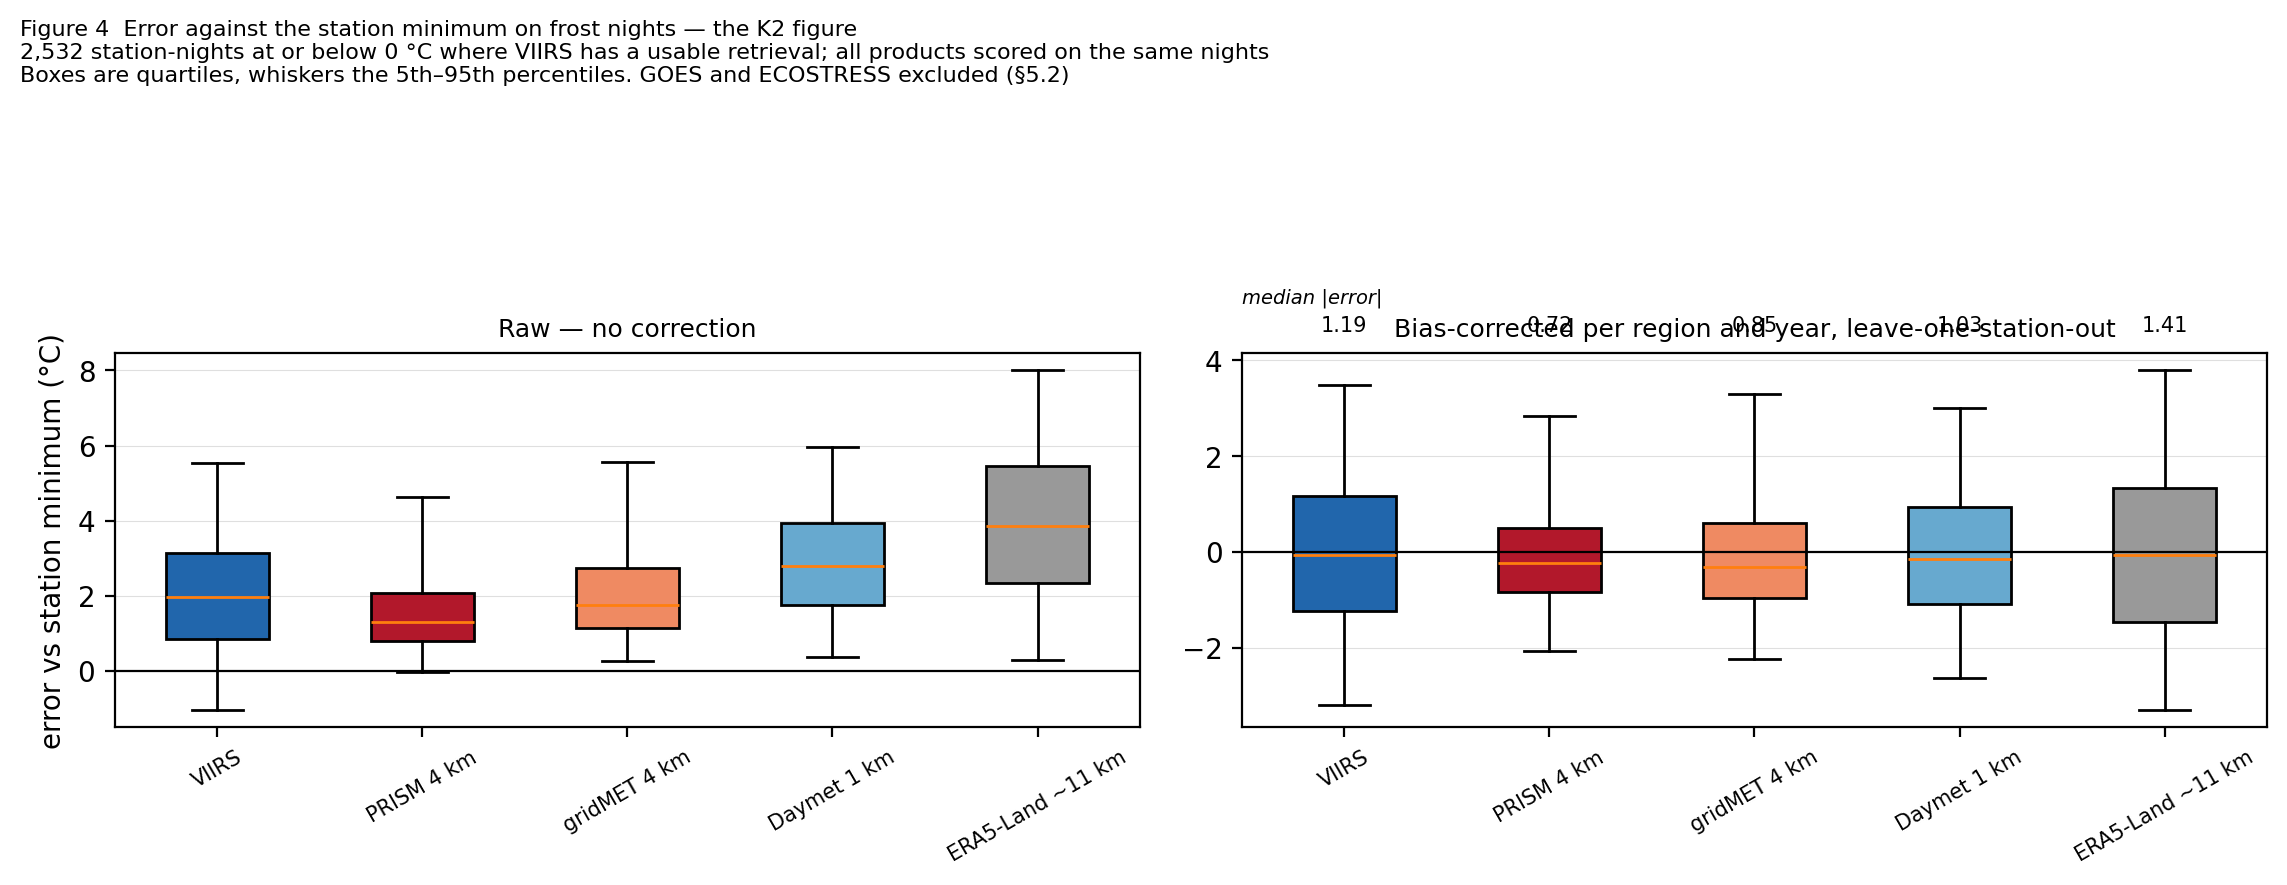

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), dpi=200)
order = list(corr_tbl["product"])
colors = {"VIIRS": "#2166ac", "PRISM 4 km": "#b2182b", "gridMET 4 km": "#ef8a62",
          "Daymet 1 km": "#67a9cf", "ERA5-Land ~11 km": "#999999"}

ax = axes[0]
data = [raw_errors(matched, "viirs_lst_c")] + [raw_errors(matched, g) for g in GRIDS]
labs = ["VIIRS"] + [GRID_LABEL[g] for g in GRIDS]
bp = ax.boxplot(data, labels=labs, showfliers=False, patch_artist=True, whis=(5, 95))
for patch, lab in zip(bp["boxes"], labs):
    patch.set_facecolor(colors.get(lab, "#cccccc"))
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("error vs station minimum (°C)")
ax.set_title("Raw — no correction", fontsize=9)
ax.tick_params(axis="x", labelrotation=30, labelsize=7.5)
ax.grid(axis="y", lw=0.4, alpha=0.4)
ax.set_axisbelow(True)

ax = axes[1]
data = [loso_errors(matched, "viirs_lst_c")] + [loso_errors(matched, g) for g in GRIDS]
bp = ax.boxplot(data, labels=labs, showfliers=False, patch_artist=True, whis=(5, 95))
for patch, lab in zip(bp["boxes"], labs):
    patch.set_facecolor(colors.get(lab, "#cccccc"))
ax.axhline(0, color="k", lw=0.8)
ax.set_title("Bias-corrected per region and year, leave-one-station-out", fontsize=9)
ax.tick_params(axis="x", labelrotation=30, labelsize=7.5)
ax.grid(axis="y", lw=0.4, alpha=0.4)
ax.set_axisbelow(True)
for i, d in enumerate(data, start=1):
    ax.text(i, 4.6, f"{d.abs().median():.2f}", ha="center", fontsize=7.5)
ax.text(0.5, 5.2, "median |error|", fontsize=7, style="italic")

fig.suptitle("Figure 4  Error against the station minimum on frost nights — the K2 figure\n"
             f"{len(matched):,} station-nights at or below 0 °C where VIIRS has a usable "
             "retrieval; all products scored on the same nights\n"
             "Boxes are quartiles, whiskers the 5th–95th percentiles. GOES and ECOSTRESS "
             "excluded (§5.2)",
             fontsize=8, x=0.005, y=0.995, ha="left", va="top")
fig.tight_layout(rect=(0, 0, 1, 0.88))
fig.savefig(C.FIGURES / "fig04_error_distributions.png", dpi=200, bbox_inches="tight")
print(f"Figure 4: {len(matched):,} matched station-nights, {len(labs)} products")
print("saved figures/fig04_error_distributions.png")

In [8]:
m.to_csv(C.DERIVED / "04_point_comparison.csv", index=False)
corr_tbl.to_csv(C.DERIVED / "04_headline_corrected.csv", index=False)
raw_tbl.to_csv(C.DERIVED / "04_headline_raw.csv", index=False)
by_thr.to_csv(C.DERIVED / "04_by_threshold.csv", index=False)
region_tbl.to_csv(C.DERIVED / "04_by_region.csv", index=False)
sens_tbl.to_csv(C.DERIVED / "04_stratification_sensitivity.csv", index=False)

print("=" * 78)
print("STEP 4 CHECKPOINT SUMMARY — every figure with its denominator")
print("=" * 78)
print(f"station-nights joined                          {len(m):>8,}")
print(f"  frost nights at 0 °C                         {int(m.frost.sum()):>8,}")
print(f"  of those, VIIRS has a usable retrieval       {len(matched):>8,}   "
      f"(the matched subset)")
print(f"day alignment chosen for all four grids        {'0 days':>8}")
print("\nMdAE on the matched subset, bias-corrected, leave-one-station-out:")
for p in corr_tbl["product"]:
    print(f"  {p:<22} {v.loc[p, 'MdAE']:>6.2f} °C")
print(f"\nK2                                             {'FIRES':>8}")
print(f"stratification sensitivity: ranking unchanged under all "
      f"{len(C.REGION_SCHEMES)} schemes")
print("\nwrote data/derived/: 04_point_comparison.csv, 04_headline_corrected.csv,")
print("      04_headline_raw.csv, 04_by_threshold.csv, 04_by_region.csv,")
print("      04_stratification_sensitivity.csv; figures/fig04_error_distributions.png")

STEP 4 CHECKPOINT SUMMARY — every figure with its denominator
station-nights joined                            31,359
  frost nights at 0 °C                            2,910
  of those, VIIRS has a usable retrieval          2,532   (the matched subset)
day alignment chosen for all four grids          0 days

MdAE on the matched subset, bias-corrected, leave-one-station-out:
  PRISM 4 km               0.72 °C
  gridMET 4 km             0.85 °C
  Daymet 1 km              1.03 °C
  VIIRS                    1.19 °C
  ERA5-Land ~11 km         1.41 °C

K2                                                FIRES
stratification sensitivity: ranking unchanged under all 5 schemes

wrote data/derived/: 04_point_comparison.csv, 04_headline_corrected.csv,
      04_headline_raw.csv, 04_by_threshold.csv, 04_by_region.csv,
      04_stratification_sensitivity.csv; figures/fig04_error_distributions.png
